<a href="https://colab.research.google.com/github/SaidHoffman/Aplicacion-c-s-tipo-Drive/blob/rodrigo/Practica3_NLP_.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# PRÁCTICA 3: IDENTIFICACIÓN DE FRASES CLAVE Y RESUMEN AUTOMÁTICO DE TEXTO

**Estudiante:** Sigala Morales Said

**Grupo:** 5BV1

**Carrera:** Ingeniería en Sistemas Computacionales

**Fecha de última modificación:** 04 de Noviembre de 2025

**Descripción:** Este programa implementa seis algoritmos diferentes para extracción de frases clave y resumen automático de texto, aplicados a las cuatro primeras cartas del libro Frankenstein de Mary Shelley. Los algoritmos implementados son: TF-IDF, Frecuencia de Palabras Normalizada, RAKE, TextRank, BERT y LSA.

**Funciones principales:**
- `descargar_frankenstein()`: Carga el texto de las cartas desde una constante incluida en el código
- `extraer_cartas()`: Extrae las 4 primeras cartas del libro
- `normalizar_texto()`: Aplica técnicas de normalización a los textos
- `resumen_tfidf()`: Genera resumen usando TF-IDF
- `resumen_frecuencia()`: Genera resumen usando frecuencia de palabras normalizada
- `resumen_rake()`: Genera resumen usando RAKE
- `resumen_textrank()`: Genera resumen usando TextRank
- `resumen_bert()`: Genera resumen usando BERT
- `resumen_lsa()`: Genera resumen usando LSA
- `comparar_algoritmos()`: Compara y mide tiempos de ejecución

## 1. Instalación de Librerías Necesarias

In [ ]:
# === Setup mínimo sin try/except ===
import sys, subprocess
import nltk, spacy

# Instalar dependencias (si ya están, pip las dejará tal cual)
subprocess.check_call([sys.executable, "-m", "pip", "install",
    "nltk", "spacy", "rake-nltk", "networkx", "sumy", "transformers",
    "scikit-learn", "gensim", "en_core_web_sm", "-q"
])

for res in ["punkt", "punkt_tab", "stopwords", "wordnet", "omw-1.4"]:
    nltk.download(res, quiet=True)

# Cargar modelo de spaCy
nlp = spacy.load("en_core_web_sm")

nltk.download("punkt", quiet=True)
nltk.download("stopwords", quiet=True)
nltk.download("wordnet", quiet=True)
nltk.download("averaged_perceptron_tagger", quiet=True)

True

## 2. Importación de Bibliotecas

In [ ]:
# ==== Importaciones mínimas y ordenadas ====
import warnings
warnings.filterwarnings("ignore")

# Estándar
import re
import time
from collections import Counter

# Numérico
import numpy as np

# NLP clásico
import nltk
from nltk.corpus import stopwords
from nltk.tokenize import sent_tokenize, word_tokenize
from nltk.stem import WordNetLemmatizer

# NLP avanzado
import spacy

# RAKE (frases clave)
from rake_nltk import Rake

# Grafos (TextRank manual si lo necesitas)
import networkx as nx

# TF-IDF / LSA / similitud
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.decomposition import TruncatedSVD
from sklearn.metrics.pairwise import cosine_similarity

# Sumy (implementaciones de TextRank y LSA listas)
from sumy.parsers.plaintext import PlaintextParser
from sumy.nlp.tokenizers import Tokenizer
from sumy.summarizers.text_rank import TextRankSummarizer
from sumy.summarizers.lsa import LsaSummarizer

# Transformers (embeddings/clasificación extractiva con BERT)
from transformers import pipeline

print("✓ Importaciones realizadas")


✓ Importaciones realizadas


## 3. Generación del Cuerpo de Documentos (0 pts)

En esta sección cargamos las cuatro primeras cartas del libro Frankenstein que están incluidas directamente en el código.

In [ ]:
carta1 = """Letter 1
To Mrs. Saville, England.

St. Petersburgh, Dec. 11th, 17—.

You will rejoice to hear that no disaster has accompanied the commencement of an enterprise which you have regarded with such evil forebodings. I arrived here yesterday, and my first task is to assure my dear sister of my welfare and increasing confidence in the success of my undertaking.

I am already far north of London, and as I walk in the streets of Petersburgh, I feel a cold northern breeze play upon my cheeks, which braces my nerves and fills me with delight. Do you understand this feeling? This breeze, which has travelled from the regions towards which I am advancing, gives me a foretaste of those icy climes. Inspirited by this wind of promise, my daydreams become more fervent and vivid. I try in vain to be persuaded that the pole is the seat of frost and desolation; it ever presents itself to my imagination as the region of beauty and delight. There, Margaret, the sun is for ever visible, its broad disk just skirting the horizon and diffusing a perpetual splendour. There—for with your leave, my sister, I will put some trust in preceding navigators—there snow and frost are banished; and, sailing over a calm sea, we may be wafted to a land surpassing in wonders and in beauty every region hitherto discovered on the habitable globe. Its productions and features may be without example, as the phenomena of the heavenly bodies undoubtedly are in those undiscovered solitudes. What may not be expected in a country of eternal light? I may there discover the wondrous power which attracts the needle and may regulate a thousand celestial observations that require only this voyage to render their seeming eccentricities consistent for ever. I shall satiate my ardent curiosity with the sight of a part of the world never before visited, and may tread a land never before imprinted by the foot of man. These are my enticements, and they are sufficient to conquer all fear of danger or death and to induce me to commence this laborious voyage with the joy a child feels when he embarks in a little boat, with his holiday mates, on an expedition of discovery up his native river. But supposing all these conjectures to be false, you cannot contest the inestimable benefit which I shall confer on all mankind, to the last generation, by discovering a passage near the pole to those countries, to reach which at present so many months are requisite; or by ascertaining the secret of the magnet, which, if at all possible, can only be effected by an undertaking such as mine.

These reflections have dispelled the agitation with which I began my letter, and I feel my heart glow with an enthusiasm which elevates me to heaven, for nothing contributes so much to tranquillise the mind as a steady purpose—a point on which the soul may fix its intellectual eye. This expedition has been the favourite dream of my early years. I have read with ardour the accounts of the various voyages which have been made in the prospect of arriving at the North Pacific Ocean through the seas which surround the pole. You may remember that a history of all the voyages made for purposes of discovery composed the whole of our good Uncle Thomas' library. My education was neglected, yet I was passionately fond of reading. These volumes were my study day and night, and my familiarity with them increased that regret which I had felt, as a child, on learning that my father's dying injunction had forbidden my uncle to allow me to embark in a seafaring life.

These visions faded when I perused, for the first time, those poets whose effusions entranced my soul and lifted it to heaven. I also became a poet and for one year lived in a paradise of my own creation; I imagined that I also might obtain a niche in the temple where the names of Homer and Shakespeare are consecrated. You are well acquainted with my failure and how heavily I bore the disappointment. But just at that time I inherited the fortune of my cousin, and my thoughts were turned into the channel of their earlier bent.

Six years have passed since I resolved on my present undertaking. I can, even now, remember the hour from which I dedicated myself to this great enterprise. I commenced by inuring my body to hardship. I accompanied the whale-fishers on several expeditions to the North Sea; I voluntarily endured cold, famine, thirst, and want of sleep; I often worked harder than the common sailors during the day and devoted my nights to the study of mathematics, the theory of medicine, and those branches of physical science from which a naval adventurer might derive the greatest practical advantage. Twice I actually hired myself as an under-mate in a Greenland whaler, and acquitted myself to admiration. I must own I felt a little proud when my captain offered me the second dignity in the vessel and entreated me to remain with the greatest earnestness, so valuable did he consider my services.

And now, dear Margaret, do I not deserve to accomplish some great purpose? My life might have been passed in ease and luxury, but I preferred glory to every enticement that wealth placed in my path. Oh, that some encouraging voice would answer in the affirmative! My courage and my resolution is firm; but my hopes fluctuate, and my spirits are often depressed. I am about to proceed on a long and difficult voyage, the emergencies of which will demand all my fortitude: I am required not only to raise the spirits of others, but sometimes to sustain my own, when theirs are failing.

This is the most favourable period for travelling in Russia. They fly quickly over the snow in their sledges; the motion is pleasant, and, in my opinion, far more agreeable than that of an English stagecoach. The cold is not excessive, if you are wrapped in furs—a dress which I have already adopted, for there is a great difference between walking the deck and remaining seated motionless for hours, when no exercise prevents the blood from actually freezing in your veins. I have no ambition to lose my life on the post-road between St. Petersburgh and Archangel.

I shall depart for the latter town in a fortnight or three weeks; and my intention is to hire a ship there, which can easily be done by paying the insurance for the owner, and to engage as many sailors as I think necessary among those who are accustomed to the whale-fishing. I do not intend to sail until the month of June; and when shall I return? Ah, dear sister, how can I answer this question? If I succeed, many, many months, perhaps years, will pass before you and I may meet. If I fail, you will see me again soon, or never.

Farewell, my dear, excellent Margaret. Heaven shower down blessings on you, and save me, that I may again and again testify my gratitude for all your love and kindness.

Your affectionate brother,
R. Walton
"""

carta2 = """To Mrs. Saville, England.

Archangel, 28th March, 17—.

How slowly the time passes here, encompassed as I am by frost and snow! Yet a second step is taken towards my enterprise. I have hired a vessel and am occupied in collecting my sailors; those whom I have already engaged appear to be men on whom I can depend and are certainly possessed of dauntless courage.

But I have one want which I have never yet been able to satisfy, and the absence of the object of which I now feel as a most severe evil, I have no friend, Margaret: when I am glowing with the enthusiasm of success, there will be none to participate my joy; if I am assailed by disappointment, no one will endeavour to sustain me in dejection. I shall commit my thoughts to paper, it is true; but that is a poor medium for the communication of feeling. I desire the company of a man who could sympathise with me, whose eyes would reply to mine. You may deem me romantic, my dear sister, but I bitterly feel the want of a friend. I have no one near me, gentle yet courageous, possessed of a cultivated as well as of a capacious mind, whose tastes are like my own, to approve or amend my plans. How would such a friend repair the faults of your poor brother! I am too ardent in execution and too impatient of difficulties. But it is a still greater evil to me that I am self-educated: for the first fourteen years of my life I ran wild on a common and read nothing but our Uncle Thomas’ books of voyages. At that age I became acquainted with the celebrated poets of our own country; but it was only when it had ceased to be in my power to derive its most important benefits from such a conviction that I perceived the necessity of becoming acquainted with more languages than that of my native country. Now I am twenty-eight and am in reality more illiterate than many schoolboys of fifteen. It is true that I have thought more and that my daydreams are more extended and magnificent, but they want (as the painters call it) keeping; and I greatly need a friend who would have sense enough not to despise me as romantic, and affection enough for me to endeavour to regulate my mind.

Well, these are useless complaints; I shall certainly find no friend on the wide ocean, nor even here in Archangel, among merchants and seamen. Yet some feelings, unallied to the dross of human nature, beat even in these rugged bosoms. My lieutenant, for instance, is a man of wonderful courage and enterprise; he is madly desirous of glory, or rather, to word my phrase more characteristically, of advancement in his profession. He is an Englishman, and in the midst of national and professional prejudices, unsoftened by cultivation, retains some of the noblest endowments of humanity. I first became acquainted with him on board a whale vessel; finding that he was unemployed in this city, I easily engaged him to assist in my enterprise.

The master is a person of an excellent disposition and is remarkable in the ship for his gentleness and the mildness of his discipline. This circumstance, added to his well-known integrity and dauntless courage, made me very desirous to engage him. A youth passed in solitude, my best years spent under your gentle and feminine fosterage, has so refined the groundwork of my character that I cannot overcome an intense distaste to the usual brutality exercised on board ship: I have never believed it to be necessary, and when I heard of a mariner equally noted for his kindliness of heart and the respect and obedience paid to him by his crew, I felt myself peculiarly fortunate in being able to secure his services. I heard of him first in rather a romantic manner, from a lady who owes to him the happiness of her life. This, briefly, is his story. Some years ago he loved a young Russian lady of moderate fortune, and having amassed a considerable sum in prize-money, the father of the girl consented to the match. He saw his mistress once before the destined ceremony; but she was bathed in tears, and throwing herself at his feet, entreated him to spare her, confessing at the same time that she loved another, but that he was poor, and that her father would never consent to the union. My generous friend reassured the suppliant, and on being informed of the name of her lover, instantly abandoned his pursuit. He had already bought a farm with his money, on which he had designed to pass the remainder of his life; but he bestowed the whole on his rival, together with the remains of his prize-money to purchase stock, and then himself solicited the young woman’s father to consent to her marriage with her lover. But the old man decidedly refused, thinking himself bound in honour to my friend, who, when he found the father inexorable, quitted his country, nor returned until he heard that his former mistress was married according to her inclinations. “What a noble fellow!” you will exclaim. He is so; but then he is wholly uneducated: he is as silent as a Turk, and a kind of ignorant carelessness attends him, which, while it renders his conduct the more astonishing, detracts from the interest and sympathy which otherwise he would command.

Yet do not suppose, because I complain a little or because I can conceive a consolation for my toils which I may never know, that I am wavering in my resolutions. Those are as fixed as fate, and my voyage is only now delayed until the weather shall permit my embarkation. The winter has been dreadfully severe, but the spring promises well, and it is considered as a remarkably early season, so that perhaps I may sail sooner than I expected. I shall do nothing rashly: you know me sufficiently to confide in my prudence and considerateness whenever the safety of others is committed to my care.

I cannot describe to you my sensations on the near prospect of my undertaking. It is impossible to communicate to you a conception of the trembling sensation, half pleasurable and half fearful, with which I am preparing to depart. I am going to unexplored regions, to “the land of mist and snow,” but I shall kill no albatross; therefore do not be alarmed for my safety or if I should come back to you as worn and woeful as the “Ancient Mariner.” You will smile at my allusion, but I will disclose a secret. I have often attributed my attachment to, my passionate enthusiasm for, the dangerous mysteries of ocean to that production of the most imaginative of modern poets. There is something at work in my soul which I do not understand. I am practically industrious—painstaking, a workman to execute with perseverance and labour—but besides this there is a love for the marvellous, a belief in the marvellous, intertwined in all my projects, which hurries me out of the common pathways of men, even to the wild sea and unvisited regions I am about to explore.

But to return to dearer considerations. Shall I meet you again, after having traversed immense seas, and returned by the most southern cape of Africa or America? I dare not expect such success, yet I cannot bear to look on the reverse of the picture. Continue for the present to write to me by every opportunity: I may receive your letters on some occasions when I need them most to support my spirits. I love you very tenderly. Remember me with affection, should you never hear from me again.

Your affectionate brother,
Robert Walton
"""

carta3 = """Letter 3
To Mrs. Saville, England.

July 7th, 17—.

My dear Sister,

I write a few lines in haste to say that I am safe—and well advanced on my voyage. This letter will reach England by a merchantman now on its homeward voyage from Archangel; more fortunate than I, who may not see my native land, perhaps, for many years. I am, however, in good spirits: my men are bold and apparently firm of purpose, nor do the floating sheets of ice that continually pass us, indicating the dangers of the region towards which we are advancing, appear to dismay them. We have already reached a very high latitude; but it is the height of summer, and although not so warm as in England, the southern gales, which blow us speedily towards those shores which I so ardently desire to attain, breathe a degree of renovating warmth which I had not expected.

No incidents have hitherto befallen us that would make a figure in a letter. One or two stiff gales and the springing of a leak are accidents which experienced navigators scarcely remember to record, and I shall be well content if nothing worse happen to us during our voyage.

Adieu, my dear Margaret. Be assured that for my own sake, as well as yours, I will not rashly encounter danger. I will be cool, persevering, and prudent.

But success shall crown my endeavours. Wherefore not? Thus far I have gone, tracing a secure way over the pathless seas, the very stars themselves being witnesses and testimonies of my triumph. Why not still proceed over the untamed yet obedient element? What can stop the determined heart and resolved will of man?

My swelling heart involuntarily pours itself out thus. But I must finish. Heaven bless my beloved sister!

R.W.
"""

carta4 = """Letter 4
To Mrs. Saville, England.

August 5th, 17—.

So strange an accident has happened to us that I cannot forbear recording it, although it is very probable that you will see me before these papers can come into your possession.

Last Monday (July 31st) we were nearly surrounded by ice, which closed in the ship on all sides, scarcely leaving her the sea-room in which she floated. Our situation was somewhat dangerous, especially as we were compassed round by a very thick fog. We accordingly lay to, hoping that some change would take place in the atmosphere and weather.

About two o'clock the mist cleared away, and we beheld, stretched out in every direction, vast and irregular plains of ice, which seemed to have no end. Some of my comrades groaned, and my own mind began to grow watchful with anxious thoughts, when a strange sight suddenly attracted our attention and diverted our solicitude from our own situation. We perceived a low carriage, fixed on a sledge and drawn by dogs, pass on towards the north, at the distance of half a mile; a being which had the shape of a man, but apparently of gigantic stature, sat in the sledge and guided the dogs. We watched the rapid progress of the traveller with our telescopes until he was lost among the distant inequalities of the ice.

This appearance excited our unqualified wonder. We were, as we believed, many hundred miles from any land; but this apparition seemed to denote that it was not, in reality, so distant as we had supposed. Shut in, however, by ice, it was impossible to follow his track, which we had observed with the greatest attention.

About two hours after this occurrence we heard the ground sea, and before night the ice broke and freed our ship. We, however, lay to until the morning, fearing to encounter in the dark those large loose masses which float about after the breaking up of the ice. I profited of this time to rest for a few hours.

In the morning, however, as soon as it was light, I went upon deck and found all the sailors busy on one side of the vessel, apparently talking to someone in the sea. It was, in fact, a sledge, like that we had seen before, which had drifted towards us in the night on a large fragment of ice. Only one dog remained alive; but there was a human being within it whom the sailors were persuading to enter the vessel. He was not, as the other traveller seemed to be, a savage inhabitant of some undiscovered island, but a European. When I appeared on deck the master said, Here is our captain, and he will not allow you to perish on the open sea.

On perceiving me, the stranger addressed me in English, although with a foreign accent. Before I come on board your vessel, said he, will you have the kindness to inform me whither you are bound?

You may conceive my astonishment on hearing such a question addressed to me from a man on the brink of destruction and to whom I should have supposed that my vessel would have been a resource which he would not have exchanged for the most precious wealth the earth can afford. I replied, however, that we were on a voyage of discovery towards the northern pole.

Upon hearing this he appeared satisfied and consented to come on board. Good God! Margaret, if you had seen the man who thus capitulated for his safety, your surprise would have been boundless. His limbs were nearly frozen, and his body dreadfully emaciated by fatigue and suffering. I never saw a man in so wretched a condition. We attempted to carry him into the cabin, but as soon as he had quitted the fresh air he fainted. We accordingly brought him back to the deck and restored him to animation by rubbing him with brandy and forcing him to swallow a small quantity. As soon as he showed signs of life we wrapped him up in blankets and placed him near the chimney of the kitchen stove. By slow degrees he recovered and ate a little soup, which restored him wonderfully.

Two days passed in this manner before he was able to speak, and I often feared that his sufferings had deprived him of understanding. When he had in some measure recovered, I removed him to my own cabin and attended on him as much as my duty would permit. I never saw a more interesting creature: his eyes have generally an expression of wildness, and even madness, but there are moments when, if anyone performs an act of kindness towards him or does him any the most trifling service, his whole countenance is lighted up, as it were, with a beam of benevolence and sweetness that I never saw equalled. But he is generally melancholy and despairing, and sometimes he gnashes his teeth, as if impatient of the weight of woes that oppresses him.

When my guest was a little recovered I had great trouble to keep off the men, who wished to ask him a thousand questions; but I would not allow him to be tormented by their idle curiosity, in a state of body and mind whose restoration evidently depended upon entire repose. Once, however, the lieutenant asked why he had come so far upon the ice in so strange a vehicle.

His countenance instantly assumed an aspect of the deepest gloom, and he replied, To seek one who fled from me.

And did the man whom you pursued travel in the same fashion?

Yes.

Then I fancy we have seen him, for the day before we picked you up we saw some dogs drawing a sledge, with a man in it, across the ice.

This aroused the stranger's attention, and he asked a multitude of questions concerning the route which the daemon, as he called him, had pursued. Soon after, when he was alone with me, he said, I have, doubtless, excited your curiosity, as well as that of these good people; but you are too considerate to make inquiries.

Certainly; it would indeed be very impertinent and inhuman in me to trouble you with any inquisitiveness of mine.

And yet you rescued me from a strange and perilous situation; you have benevolently restored me to life.

Soon after this he inquired if I thought that the breaking up of the ice had destroyed the other sledge. I replied that I could not answer with any degree of certainty, for the ice had not broken until near midnight, and the traveller might have arrived at a place of safety before that time; but of this I could not judge.

From this time a new spirit of life animated the decaying frame of the stranger. He manifested the greatest eagerness to be upon deck to watch for the sledge which had before appeared; but I have persuaded him to remain in the cabin, for he is far too weak to sustain the rawness of the atmosphere. I have promised that someone should watch for him and give him instant notice if any new object should appear in sight.

Such is my journal of what relates to this strange occurrence up to the present day. The stranger has gradually improved in health but is very silent and appears uneasy when anyone except myself enters his cabin. Yet his manners are so conciliating and gentle that the sailors are all interested in him, although they have had very little communication with him. For my own part, I begin to love him as a brother, and his constant and deep grief fills me with sympathy and compassion. He must have been a noble creature in his better days, being even now in wreck so attractive and amiable.

I said in one of my letters, my dear Margaret, that I should find no friend on the wide ocean; yet I have found a man who, before his spirit had been broken by misery, I should have been happy to have possessed as the brother of my heart.

I shall continue my journal concerning the stranger at intervals, should I have any fresh incidents to record.

August 13th, 17—.

My affection for my guest increases every day. He excites at once my admiration and my pity to an astonishing degree. How can I see so noble a creature destroyed by misery without feeling the most poignant grief? He is so gentle, yet so wise; his mind is so cultivated, and when he speaks, although his words are culled with the choicest art, yet they flow with rapidity and unparalleled eloquence.

He is now much recovered from his illness and is continually on the deck, apparently watching for the sledge that preceded his own. Yet, although unhappy, he is not so utterly occupied by his own misery but that he interests himself deeply in the projects of others. He has frequently conversed with me on mine, which I have communicated to him without disguise. He entered attentively into all my arguments in favour of my eventual success and into every minute detail of the measures I had taken to secure it. I was easily led by the sympathy which he evinced to use the language of my heart, to give utterance to the burning ardour of my soul and to say, with all the fervour that warmed me, how gladly I would sacrifice my fortune, my existence, my every hope, to the furtherance of my enterprise. One man's life or death were but a small price to pay for the acquirement of the knowledge which I sought, for the dominion I should acquire and transmit over the elemental foes of our race. As I spoke, a dark gloom spread over my listener's countenance. At first I perceived that he tried to suppress his emotion; he placed his hands before his eyes, and my voice quivered and failed me as I beheld tears trickle fast from between his fingers; a groan burst from his heaving breast. I paused; at length he spoke, in broken accents: Unhappy man! Do you share my madness? Have you drunk also of the intoxicating draught? Hear me; let me reveal my tale, and you will dash the cup from your lips!

Such words, you may imagine, strongly excited my curiosity; but the paroxysm of grief that had seized the stranger overcame his weakened powers, and many hours of repose and tranquil conversation were necessary to restore his composure.

Having conquered the violence of his feelings, he appeared to despise himself for being the slave of passion; and quelling the dark tyranny of despair, he led me again to converse concerning myself personally. He asked me the history of my earlier years. The tale was quickly told, but it awakened various trains of reflection. I spoke of my desire of finding a friend, of my thirst for a more intimate sympathy with a fellow mind than had ever fallen to my lot, and expressed my conviction that a man could boast of little happiness who did not enjoy this blessing.

I agree with you, replied the stranger; we are unfashioned creatures, but half made up, if one wiser, better, dearer than ourselves—such a friend ought to be—do not lend his aid to perfectionate our weak and faulty natures. I once had a friend, the most noble of human creatures, and am entitled, therefore, to judge respecting friendship. You have hope, and the world before you, and have no cause for despair. But I—I have lost everything and cannot begin life anew.

As he said this his countenance became expressive of a calm, settled grief that touched me to the heart. But he was silent and presently retired to his cabin.

Even broken in spirit as he is, no one can feel more deeply than he does the beauties of nature. The starry sky, the sea, and every sight afforded by these wonderful regions seem still to have the power of elevating his soul from earth. Such a man has a double existence: he may suffer misery and be overwhelmed by disappointments, yet when he has retired into himself, he will be like a celestial spirit that has a halo around him, within whose circle no grief or folly ventures.

Will you smile at the enthusiasm I express concerning this divine wanderer? You would not if you saw him. You have been tutored and refined by books and retirement from the world, and you are therefore somewhat fastidious; but this only renders you the more fit to appreciate the extraordinary merits of this wonderful man. Sometimes I have endeavoured to discover what quality it is which he possesses that elevates him so immeasurably above any other person I ever knew. I believe it to be an intuitive discernment, a quick but never-failing power of judgment, a penetration into the causes of things, unequalled for clearness and precision; add to this a facility of expression and a voice whose varied intonations are soul-subduing music.

August 19th, 17—.

Yesterday the stranger said to me, You may easily perceive, Captain Walton, that I have suffered great and unparalleled misfortunes. I had determined at one time that the memory of these evils should die with me, but you have won me to alter my determination. You seek for knowledge and wisdom, as I once did; and I ardently hope that the gratification of your wishes may not be a serpent to sting you, as mine has been. I do not know that the relation of my disasters will be useful to you; yet, when I reflect that you are pursuing the same course, exposing yourself to the same dangers which have rendered me what I am, I imagine that you may deduce an apt moral from my tale, one that may direct you if you succeed in your undertaking and console you in case of failure. Prepare to hear of occurrences which are usually deemed marvellous. Were we among the tamer scenes of nature I might fear to encounter your unbelief, perhaps your ridicule; but many things will appear possible in these wild and mysterious regions which would provoke the laughter of those unacquainted with the ever-varied powers of nature; nor can I doubt but that my tale conveys in its series internal evidence of the truth of the events of which it is composed.

You may easily imagine that I was much gratified by the offered communication, yet I could not endure that he should renew his grief by a recital of his misfortunes. I felt the greatest eagerness to hear the promised narrative, partly from curiosity and partly from a strong desire to ameliorate his fate if it were in my power. I expressed these feelings in my answer.

I thank you, he replied, for your sympathy, but it is useless; my fate is nearly fulfilled. I wait but for one event, and then I shall repose in peace. I understand your feeling, continued he, perceiving that I wished to interrupt him; but you are mistaken, my friend, if thus you will allow me to name you; nothing can alter my destiny; listen to my history, and you will perceive how irrevocably it is determined.

He then told me that he would commence his narrative the next day when I should be at leisure. This promise drew from me the warmest thanks. I have resolved every night, when I am not imperatively occupied by my duties, to record, as nearly as possible in his own words, what he has related during the day. If I should be engaged, I will at least make notes. This manuscript will doubtless afford you the greatest pleasure; but to me, who know him, and who hear it from his own lips—with what interest and sympathy shall I read it in some future day! Even now, as I commence my task, his full-toned voice swells in my ears; his lustrous eyes dwell on me with all their melancholy sweetness; I see his thin hand raised in animation, while the lineaments of his face are irradiated by the soul within. Strange and harrowing must be his story, frightful the storm which embraced the gallant vessel on its course and wrecked it—thus!
"""

cartas = [carta1, carta2, carta3, carta4]

# Ejecutar la carga y extracción
print("=" * 60)
print("PASO 1: GENERACIÓN DEL CUERPO DE DOCUMENTOS")
print("=" * 60)

print(f"\n✓ Total de cartas extraídas: {len(cartas)}")
print(f"\nLongitud de cada carta:")
for i, carta in enumerate(cartas, 1):
    print(f"  Carta {i}: {len(carta.split())} palabras")

PASO 1: GENERACIÓN DEL CUERPO DE DOCUMENTOS

✓ Total de cartas extraídas: 4

Longitud de cada carta:
  Carta 1: 1200 palabras
  Carta 2: 1309 palabras
  Carta 3: 300 palabras
  Carta 4: 2730 palabras


## 4. Normalización de Textos (10 pts)

Aplicamos técnicas de normalización a las cartas para prepararlas para el análisis. Las técnicas incluyen:
- Conversión a minúsculas
- Eliminación de caracteres especiales y números
- Tokenización
- Eliminación de stopwords
- Lematización

In [ ]:
# Inicializar herramientas de normalización
stop_words = set(stopwords.words('english'))
lemmatizer = WordNetLemmatizer()
nlp = spacy.load('en_core_web_sm')

def normalizar_texto(texto):
    """
    Normaliza el texto aplicando varias técnicas de preprocesamiento.

    Técnicas aplicadas:
    1. Conversión a minúsculas para uniformidad
    2. Eliminación de caracteres especiales y números
    3. Tokenización en oraciones y palabras
    4. Eliminación de stopwords (palabras comunes sin significado)
    5. Lematización (reducción a forma base de las palabras)

    Args:
        texto (str): Texto a normalizar

    Returns:
        dict: Diccionario con el texto original y normalizado
    """
    # 1. Conversión a minúsculas
    texto_lower = texto.lower()

    # 2. Eliminación de caracteres especiales manteniendo puntos para oraciones
    texto_limpio = re.sub(r'[^a-zA-Z\s\.]', '', texto_lower)

    # 3. Tokenización en oraciones (necesaria para resumen)
    oraciones = sent_tokenize(texto)

    # 4. Tokenización en palabras
    palabras = word_tokenize(texto_limpio)

    # 5. Eliminación de stopwords y lematización
    palabras_normalizadas = [
        lemmatizer.lemmatize(palabra)
        for palabra in palabras
        if palabra not in stop_words and len(palabra) > 2
    ]

    # Reconstruir el texto normalizado
    texto_normalizado = ' '.join(palabras_normalizadas)

    return {
        'original': texto,
        'normalizado': texto_normalizado,
        'oraciones': oraciones,
        'num_oraciones': len(oraciones),
        'num_palabras_original': len(texto.split()),
        'num_palabras_normalizado': len(palabras_normalizadas)
    }


# Normalizar todas las cartas
print("=" * 60)
print("PASO 2: NORMALIZACIÓN DE TEXTOS")
print("=" * 60)

cartas_normalizadas = []

for i, carta in enumerate(cartas, 1):
    print(f"\nNormalizando Carta {i}...")
    carta_norm = normalizar_texto(carta)
    cartas_normalizadas.append(carta_norm)

    print(f"  Oraciones: {carta_norm['num_oraciones']}")
    print(f"  Palabras originales: {carta_norm['num_palabras_original']}")
    print(f"  Palabras después de normalización: {carta_norm['num_palabras_normalizado']}")
    print(f"  Reducción: {100 - (carta_norm['num_palabras_normalizado']/carta_norm['num_palabras_original']*100):.1f}%")

print("\n✓ Normalización completada para todas las cartas")

PASO 2: NORMALIZACIÓN DE TEXTOS

Normalizando Carta 1...
  Oraciones: 50
  Palabras originales: 1200
  Palabras después de normalización: 565
  Reducción: 52.9%

Normalizando Carta 2...
  Oraciones: 50
  Palabras originales: 1309
  Palabras después de normalización: 582
  Reducción: 55.5%

Normalizando Carta 3...
  Oraciones: 20
  Palabras originales: 300
  Palabras después de normalización: 151
  Reducción: 49.7%

Normalizando Carta 4...
  Oraciones: 116
  Palabras originales: 2730
  Palabras después de normalización: 1223
  Reducción: 55.2%

✓ Normalización completada para todas las cartas


### Justificación de la Normalización

**Técnicas aplicadas:**

1. **Conversión a minúsculas**: Necesaria para que palabras como "The" y "the" se consideren iguales en el análisis de frecuencias.

2. **Eliminación de caracteres especiales**: Elimina ruido del texto que no aporta significado semántico.

3. **Tokenización**: Divide el texto en unidades manejables (oraciones y palabras) necesarias para todos los algoritmos.

4. **Eliminación de stopwords**: Remueve palabras muy frecuentes ("the", "is", "at") que no aportan al significado distintivo del texto.

5. **Lematización**: Reduce las palabras a su forma base ("running" → "run") para agrupar variaciones de la misma palabra.

**Nota**: Para los algoritmos de resumen, se utilizará el texto con tokenización básica pero sin eliminación completa de stopwords, ya que estas pueden ser importantes para la coherencia de las oraciones seleccionadas.

## 5. Implementación de Algoritmos de Resumen (30 pts)

### 5.1 TF-IDF con NLTK

In [ ]:
# === Resumen por TF-IDF (devuelve texto + índices de oraciones originales) ===
import numpy as np
from nltk.tokenize import sent_tokenize
from sklearn.feature_extraction.text import TfidfVectorizer

def resumen_tfidf(texto: str, num_oraciones: int = 12):
    """
    Genera un resumen extractivo por TF-IDF.
    Devuelve:
      - resumen_text: string con las oraciones seleccionadas (en orden original)
      - indices: lista de índices de las oraciones originales usadas
    """
    # 1) Oraciones originales (no alteres el texto para no perder puntuación)
    oraciones = sent_tokenize(texto)
    if len(oraciones) <= num_oraciones:
        return texto, list(range(len(oraciones)))

    # 2) TF-IDF con oraciones como "documentos" individuales
    vectorizer = TfidfVectorizer(stop_words="english")
    tfidf = vectorizer.fit_transform(oraciones)  # shape: (n_oraciones, n_terms)

    # 3) Puntaje = suma de pesos TF-IDF por oración
    puntajes = np.asarray(tfidf.sum(axis=1)).ravel()

    # 4) Selección de top-k
    k = min(num_oraciones, len(oraciones))
    # argpartition es O(n), más simple/rápido que argsort completo
    top_idx = np.argpartition(puntajes, -k)[-k:]
    # Mantener orden de aparición original en el texto
    top_idx = sorted(top_idx.tolist())

    # 5) Construir resumen pegando oraciones originales
    resumen_text = " ".join(oraciones[i] for i in top_idx)
    return resumen_text, top_idx

   # === ALGORITMO 1: TF-IDF (para todas las cartas) ===
import time

print("=" * 60)
print("ALGORITMO 1: TF-IDF")
print("=" * 60)

for i, carta in enumerate(cartas, 1):
    inicio = time.time()
    resumen, idx = resumen_tfidf(carta, num_oraciones=12)
    dt = time.time() - inicio

    print(f"\nCarta {i}")
    print("-" * 60)
    print(f"Tiempo de ejecución: {dt:.4f} s")
    print(f"Índices usados (orden textual): {idx}")
    print(f"Resumen:")
    print((resumen))


ALGORITMO 1: TF-IDF

Carta 1
------------------------------------------------------------
Tiempo de ejecución: 0.0047 s
Índices usados (orden textual): [4, 10, 13, 15, 16, 17, 22, 24, 30, 32, 40, 42]
Resumen:
I am already far north of London, and as I walk in the streets of Petersburgh, I feel a cold northern breeze play upon my cheeks, which braces my nerves and fills me with delight. There—for with your leave, my sister, I will put some trust in preceding navigators—there snow and frost are banished; and, sailing over a calm sea, we may be wafted to a land surpassing in wonders and in beauty every region hitherto discovered on the habitable globe. I may there discover the wondrous power which attracts the needle and may regulate a thousand celestial observations that require only this voyage to render their seeming eccentricities consistent for ever. These are my enticements, and they are sufficient to conquer all fear of danger or death and to induce me to commence this laborious vo

### 5.2 Frecuencia de Palabras Normalizada

In [ ]:
def resumen_frecuencia(texto, num_oraciones=12):
    """
    Genera resumen basado en frecuencia de palabras normalizada.

    Este método:
    1. Calcula la frecuencia de cada palabra en el texto
    2. Normaliza las frecuencias dividiéndolas por la frecuencia máxima
    3. Asigna puntuación a cada oración sumando las frecuencias de sus palabras
    4. Selecciona las oraciones con mayor puntuación

    Args:
        texto (str): Texto a resumir
        num_oraciones (int): Número de oraciones en el resumen

    Returns:
        str: Resumen del texto
    """
    # Tokenizar en oraciones
    oraciones = sent_tokenize(texto)

    if len(oraciones) <= num_oraciones:
        return texto

    # Tokenizar en palabras y calcular frecuencias
    palabras = word_tokenize(texto.lower())
    palabras_filtradas = [
        palabra for palabra in palabras
        if palabra.isalnum() and palabra not in stop_words
    ]

    # Contar frecuencias de palabras
    frecuencias = Counter(palabras_filtradas)

    # Normalizar frecuencias (dividir por la frecuencia máxima)
    max_frecuencia = max(frecuencias.values()) if frecuencias else 1
    frecuencias_normalizadas = {
        palabra: freq / max_frecuencia
        for palabra, freq in frecuencias.items()
    }

    # Calcular puntuación de cada oración
    puntuaciones_oraciones = {}
    for i, oracion in enumerate(oraciones):
        palabras_oracion = word_tokenize(oracion.lower())
        puntuacion = sum(
            frecuencias_normalizadas.get(palabra, 0)
            for palabra in palabras_oracion
        )
        puntuaciones_oraciones[i] = puntuacion

    # Seleccionar las N oraciones con mayor puntuación
    indices_ordenados = sorted(
        puntuaciones_oraciones.keys(),
        key=lambda x: puntuaciones_oraciones[x],
        reverse=True
    )[:num_oraciones]

    # Mantener orden original
    indices_ordenados = sorted(indices_ordenados)

    # Construir resumen
    resumen = ' '.join([oraciones[i] for i in indices_ordenados])
    return resumen


# Probar el algoritmo
print("=" * 60)
print("ALGORITMO 2: FRECUENCIA DE PALABRAS NORMALIZADA")
print("=" * 60)

inicio = time.time()
resumen_carta1_freq = resumen_frecuencia(cartas[0], 12)
tiempo_freq = time.time() - inicio

print(f"\nTiempo de ejecución: {tiempo_freq:.4f} segundos")
print(f"\nResumen (primeras 500 caracteres):")
print(resumen_carta1_freq[:500] + "...")

ALGORITMO 2: FRECUENCIA DE PALABRAS NORMALIZADA

Tiempo de ejecución: 0.0121 segundos

Resumen (primeras 500 caracteres):
I am already far north of London, and as I walk in the streets of Petersburgh, I feel a cold northern breeze play upon my cheeks, which braces my nerves and fills me with delight. There—for with your leave, my sister, I will put some trust in preceding navigators—there snow and frost are banished; and, sailing over a calm sea, we may be wafted to a land surpassing in wonders and in beauty every region hitherto discovered on the habitable globe. I may there discover the wondrous power which attra...


### 5.3 RAKE (Rapid Automatic Keyword Extraction)

In [ ]:
def resumen_rake(texto, num_oraciones=12):
    """
    Genera resumen usando RAKE para identificar frases clave.

    RAKE (Rapid Automatic Keyword Extraction) es un algoritmo que:
    1. Identifica palabras clave y frases basándose en su frecuencia y co-ocurrencia
    2. Calcula puntuaciones para cada frase candidata
    3. Selecciona oraciones que contienen las frases mejor puntuadas

    Args:
        texto (str): Texto a resumir
        num_oraciones (int): Número de oraciones en el resumen

    Returns:
        str: Resumen del texto
    """
    # Tokenizar en oraciones
    oraciones = sent_tokenize(texto)

    if len(oraciones) <= num_oraciones:
        return texto

    # Inicializar RAKE
    rake = Rake()

    # Extraer frases clave del texto completo
    rake.extract_keywords_from_text(texto)
    frases_clave = rake.get_ranked_phrases_with_scores()

    # Crear conjunto de palabras clave importantes
    palabras_importantes = set()
    for score, frase in frases_clave[:50]:  # Top 50 frases
        palabras_importantes.update(word_tokenize(frase.lower()))

    # Calcular puntuación de cada oración basada en palabras clave
    puntuaciones = {}
    for i, oracion in enumerate(oraciones):
        palabras_oracion = set(word_tokenize(oracion.lower()))
        # Contar cuántas palabras importantes tiene la oración
        puntuacion = len(palabras_oracion.intersection(palabras_importantes))
        puntuaciones[i] = puntuacion

    # Seleccionar oraciones con mayor puntuación
    indices_ordenados = sorted(
        puntuaciones.keys(),
        key=lambda x: puntuaciones[x],
        reverse=True
    )[:num_oraciones]

    # Mantener orden original
    indices_ordenados = sorted(indices_ordenados)

    # Construir resumen
    resumen = ' '.join([oraciones[i] for i in indices_ordenados])
    return resumen


# Probar el algoritmo
print("=" * 60)
print("ALGORITMO 3: RAKE")
print("=" * 60)

inicio = time.time()
resumen_carta1_rake = resumen_rake(cartas[0], 12)
tiempo_rake = time.time() - inicio

print(f"\nTiempo de ejecución: {tiempo_rake:.4f} segundos")
print(f"\nResumen (primeras 500 caracteres):")
print(resumen_carta1_rake[:500] + "...")

ALGORITMO 3: RAKE

Tiempo de ejecución: 0.0114 segundos

Resumen (primeras 500 caracteres):
I am already far north of London, and as I walk in the streets of Petersburgh, I feel a cold northern breeze play upon my cheeks, which braces my nerves and fills me with delight. There—for with your leave, my sister, I will put some trust in preceding navigators—there snow and frost are banished; and, sailing over a calm sea, we may be wafted to a land surpassing in wonders and in beauty every region hitherto discovered on the habitable globe. Its productions and features may be without example...


### 5.4 TextRank

In [ ]:
def resumen_textrank(texto, num_oraciones=12):
    """
    Genera resumen usando el algoritmo TextRank.

    TextRank es un algoritmo basado en grafos similar a PageRank:
    1. Representa las oraciones como nodos en un grafo
    2. Calcula similitud entre oraciones usando similitud de coseno
    3. Crea aristas entre oraciones similares
    4. Aplica PageRank para encontrar las oraciones más importantes

    Args:
        texto (str): Texto a resumir
        num_oraciones (int): Número de oraciones en el resumen

    Returns:
        str: Resumen del texto
    """
    # Tokenizar en oraciones
    oraciones = sent_tokenize(texto)

    if len(oraciones) <= num_oraciones:
        return texto

    # Usar implementación de Sumy para TextRank
    try:
        parser = PlaintextParser.from_string(texto, Tokenizer("english"))
        summarizer = TextRankSummarizer()

        # Generar resumen
        oraciones_resumen = summarizer(parser.document, num_oraciones)

        # Convertir a string
        resumen = ' '.join([str(oracion) for oracion in oraciones_resumen])
        return resumen

    except Exception as e:
        print(f"Error en TextRank: {e}")
        # Fallback: retornar primeras N oraciones
        return ' '.join(oraciones[:num_oraciones])


# Probar el algoritmo
print("=" * 60)
print("ALGORITMO 4: TEXTRANK")
print("=" * 60)

inicio = time.time()
resumen_carta1_textrank = resumen_textrank(cartas[0], 12)
tiempo_textrank = time.time() - inicio

print(f"\nTiempo de ejecución: {tiempo_textrank:.4f} segundos")
print(f"\nResumen (primeras 500 caracteres):")
print(resumen_carta1_textrank[:500] + "...")

ALGORITMO 4: TEXTRANK

Tiempo de ejecución: 0.0618 segundos

Resumen (primeras 500 caracteres):
I arrived here yesterday, and my first task is to assure my dear sister of my welfare and increasing confidence in the success of my undertaking. I am already far north of London, and as I walk in the streets of Petersburgh, I feel a cold northern breeze play upon my cheeks, which braces my nerves and fills me with delight. I try in vain to be persuaded that the pole is the seat of frost and desolation; it ever presents itself to my imagination as the region of beauty and delight. But supposing ...


### 5.5 BERT (Bidirectional Encoder Representations from Transformers)

In [ ]:
# === ALGORITMO 5: "BERT" extractivo por embeddings (simple, sin try/except) ===
import torch
import numpy as np
from nltk.tokenize import sent_tokenize
from transformers import AutoTokenizer, AutoModel
from sklearn.metrics.pairwise import cosine_similarity

# Cargar una vez (modelo pequeño y rápido)
_tok = AutoTokenizer.from_pretrained("sentence-transformers/all-MiniLM-L6-v2")
_mod = AutoModel.from_pretrained("sentence-transformers/all-MiniLM-L6-v2")

def _mean_pool(last_hidden_state, attention_mask):
    # mean pooling en posiciones no enmascaradas
    mask = attention_mask.unsqueeze(-1).expand(last_hidden_state.size()).float()
    summed = (last_hidden_state * mask).sum(dim=1)
    counts = mask.sum(dim=1).clamp(min=1e-9)
    return summed / counts

def _sentence_embeddings(sentences, max_length=128):
    enc = _tok(
        sentences,
        padding=True,
        truncation=True,
        max_length=max_length,
        return_tensors="pt"
    )
    with torch.no_grad():
        out = _mod(**enc)
    emb = _mean_pool(out.last_hidden_state, enc["attention_mask"])
    # L2-normaliza para coseno estable
    emb = torch.nn.functional.normalize(emb, p=2, dim=1)
    return emb.cpu().numpy()

def resumen_bert(texto: str, num_oraciones: int = 12):
    """
    Resumen extractivo:
      1) sent_tokenize(texto) -> oraciones
      2) embeddings por oración (MiniLM)
      3) centroide del documento
      4) top-k por similitud coseno al centroide
      5) devuelve (resumen_text, indices)
    """
    oraciones = sent_tokenize(texto)
    if len(oraciones) <= num_oraciones:
        return texto, list(range(len(oraciones)))

    emb = _sentence_embeddings(oraciones)                 # (n_oraciones, d)
    centroid = emb.mean(axis=0, keepdims=True)           # (1, d)
    scores = cosine_similarity(emb, centroid).ravel()    # similitud por oración

    k = min(num_oraciones, len(oraciones))
    top_idx = np.argpartition(scores, -k)[-k:]           # selección O(n)
    top_idx = sorted(top_idx.tolist())                   # orden textual

    resumen_text = " ".join(oraciones[i] for i in top_idx)
    return resumen_text, top_idx


### 5.6 LSA (Latent Semantic Analysis)

In [ ]:
def resumen_lsa(texto, num_oraciones=12):
    """
    Genera resumen usando LSA (Latent Semantic Analysis).

    LSA utiliza descomposición en valores singulares (SVD) para:
    1. Reducir la dimensionalidad de la matriz término-documento
    2. Descubrir conceptos latentes en el texto
    3. Seleccionar oraciones que mejor representan estos conceptos

    Args:
        texto (str): Texto a resumir
        num_oraciones (int): Número de oraciones en el resumen

    Returns:
        str: Resumen del texto
    """
    # Tokenizar en oraciones
    oraciones = sent_tokenize(texto)

    if len(oraciones) <= num_oraciones:
        return texto

    try:
        # Usar implementación de Sumy para LSA
        parser = PlaintextParser.from_string(texto, Tokenizer("english"))
        summarizer = LsaSummarizer()

        # Generar resumen
        oraciones_resumen = summarizer(parser.document, num_oraciones)

        # Convertir a string
        resumen = ' '.join([str(oracion) for oracion in oraciones_resumen])
        return resumen

    except Exception as e:
        print(f"Error en LSA con Sumy: {e}")
        print("Intentando con implementación alternativa...")

        try:
            # Método alternativo usando sklearn
            vectorizer = TfidfVectorizer(stop_words='english')
            tfidf_matrix = vectorizer.fit_transform(oraciones)

            # Aplicar SVD (Truncated SVD para matrices sparse)
            n_components = min(10, len(oraciones) - 1)
            svd = TruncatedSVD(n_components=n_components)
            matriz_reducida = svd.fit_transform(tfidf_matrix)

            # Calcular puntuación de cada oración
            puntuaciones = np.sum(np.abs(matriz_reducida), axis=1)

            # Seleccionar oraciones con mayor puntuación
            indices = np.argsort(puntuaciones)[::-1][:num_oraciones]
            indices = sorted(indices)

            resumen = ' '.join([oraciones[i] for i in indices])
            return resumen

        except Exception as e2:
            print(f"Error en LSA alternativo: {e2}")
            return ' '.join(oraciones[:num_oraciones])


# Probar el algoritmo
print("=" * 60)
print("ALGORITMO 6: LSA (Latent Semantic Analysis)")
print("=" * 60)

inicio = time.time()
resumen_carta1_lsa = resumen_lsa(cartas[0], 12)
tiempo_lsa = time.time() - inicio

print(f"\nTiempo de ejecución: {tiempo_lsa:.4f} segundos")
print(f"\nResumen (primeras 500 caracteres):")
print(resumen_carta1_lsa[:500] + "...")

ALGORITMO 6: LSA (Latent Semantic Analysis)

Tiempo de ejecución: 0.0447 segundos

Resumen (primeras 500 caracteres):
Inspirited by this wind of promise, my daydreams become more fervent and vivid. There—for with your leave, my sister, I will put some trust in preceding navigators—there snow and frost are banished; and, sailing over a calm sea, we may be wafted to a land surpassing in wonders and in beauty every region hitherto discovered on the habitable globe. What may not be expected in a country of eternal light? I may there discover the wondrous power which attracts the needle and may regulate a thousand c...


[link text](https://)## 6. Comparación de Algoritmos para Todas las Cartas

Ahora aplicaremos todos los algoritmos a las 4 cartas y compararemos sus tiempos de ejecución.

In [ ]:
import pandas as pd

def comparar_algoritmos(cartas):
    """
    Compara todos los algoritmos en todas las cartas.

    Args:
        cartas (list): Lista de textos de las cartas

    Returns:
        dict: Resultados y tiempos de cada algoritmo
    """
    algoritmos = {
        'TF-IDF': resumen_tfidf,
        'Frecuencia': resumen_frecuencia,
        'RAKE': resumen_rake,
        'TextRank': resumen_textrank,
        'BERT': resumen_bert,
        'LSA': resumen_lsa
    }

    resultados = {}
    tiempos = {}

    print("=" * 60)
    print("COMPARACIÓN DE ALGORITMOS EN LAS 4 CARTAS")
    print("=" * 60)

    for nombre_algo, funcion_algo in algoritmos.items():
        print(f"\n{'='*60}")
        print(f"Procesando con {nombre_algo}...")
        print(f"{'='*60}")

        resultados[nombre_algo] = []
        tiempos[nombre_algo] = []

        for i, carta in enumerate(cartas, 1):
            print(f"  Carta {i}...", end=' ')

            inicio = time.time()
            resumen = funcion_algo(carta, 12)
            tiempo = time.time() - inicio

            resultados[nombre_algo].append(resumen)
            tiempos[nombre_algo].append(tiempo)

            print(f"{tiempo:.4f}s")

        tiempo_total = sum(tiempos[nombre_algo])
        print(f"\n  Tiempo total para {nombre_algo}: {tiempo_total:.4f}s")

    return resultados, tiempos


# Ejecutar comparación
resultados, tiempos = comparar_algoritmos(cartas)

# Crear tabla de tiempos
print("\n" + "=" * 60)
print("TABLA DE TIEMPOS DE EJECUCIÓN (segundos)")
print("=" * 60)

df_tiempos = pd.DataFrame(tiempos, index=['Carta 1', 'Carta 2', 'Carta 3', 'Carta 4'])
df_tiempos.loc['TOTAL'] = df_tiempos.sum()
df_tiempos.loc['PROMEDIO'] = df_tiempos.iloc[:-1].mean()

print(df_tiempos.to_string())

print("\n✓ Resultados guardados en archivos de texto")

COMPARACIÓN DE ALGORITMOS EN LAS 4 CARTAS

Procesando con TF-IDF...
  Carta 1... 0.0050s
  Carta 2... 0.0041s
  Carta 3... 0.0023s
  Carta 4... 0.0067s

  Tiempo total para TF-IDF: 0.0181s

Procesando con Frecuencia...
  Carta 1... 0.0129s
  Carta 2... 0.0134s
  Carta 3... 0.0038s
  Carta 4... 0.0278s

  Tiempo total para Frecuencia: 0.0579s

Procesando con RAKE...
  Carta 1... 0.0123s
  Carta 2... 0.0120s
  Carta 3... 0.0037s
  Carta 4... 0.0171s

  Tiempo total para RAKE: 0.0451s

Procesando con TextRank...
  Carta 1... 0.0409s
  Carta 2... 0.0422s
  Carta 3... 0.0261s
  Carta 4... 0.1308s

  Tiempo total para TextRank: 0.2400s

Procesando con BERT...
  Carta 1... 1.3741s
  Carta 2... 1.4548s
  Carta 3... 0.3946s
  Carta 4... 2.9935s

  Tiempo total para BERT: 6.2169s

Procesando con LSA...
  Carta 1... 0.1559s
  Carta 2... 0.0787s
  Carta 3... 0.0485s
  Carta 4... 0.1660s

  Tiempo total para LSA: 0.4490s

TABLA DE TIEMPOS DE EJECUCIÓN (segundos)
            TF-IDF  Frecuencia      

## 7. Análisis Comparativo de Longitudes de Resumen

In [ ]:
# === ANÁLISIS DE LONGITUDES DE RESÚMENES ===
import pandas as pd
from nltk.tokenize import sent_tokenize

print("=" * 60)
print("ANÁLISIS DE LONGITUDES DE RESÚMENES")
print("=" * 60)

def _to_text(x):
    # Si el método devolvió (texto, indices), nos quedamos con el texto.
    return x if isinstance(x, str) else x[0]

longitudes = {}

for nombre_algo, resumenes in resultados.items():
    # resumenes: lista con el resumen de cada carta (str) o (str, idx)
    textos = [_to_text(r) for r in resumenes]
    longitudes[nombre_algo] = []
    for txt in textos:
        longitudes[nombre_algo].append({
            "palabras": len(txt.split()),
            "oraciones": len(sent_tokenize(txt))
        })

# Tabla: número de palabras por resumen
print("\nNÚMERO DE PALABRAS POR RESUMEN:")
df_palabras = pd.DataFrame(
    {algo: [d["palabras"] for d in longitudes[algo]] for algo in longitudes.keys()},
    index=["Carta 1", "Carta 2", "Carta 3", "Carta 4"]
)
df_palabras.loc["PROMEDIO"] = df_palabras.mean(numeric_only=True)
print(df_palabras.to_string())

# Tabla: número de oraciones por resumen
print("\n\nNÚMERO DE ORACIONES POR RESUMEN:")
df_oraciones = pd.DataFrame(
    {algo: [d["oraciones"] for d in longitudes[algo]] for algo in longitudes.keys()},
    index=["Carta 1", "Carta 2", "Carta 3", "Carta 4"]
)
df_oraciones.loc["PROMEDIO"] = df_oraciones.mean(numeric_only=True)
print(df_oraciones.to_string())


ANÁLISIS DE LONGITUDES DE RESÚMENES

NÚMERO DE PALABRAS POR RESUMEN:
          TF-IDF  Frecuencia   RAKE  TextRank   BERT     LSA
Carta 1    555.0       508.0  428.0     512.0  425.0  322.00
Carta 2    621.0       604.0  529.0     603.0  408.0  405.00
Carta 3    267.0       268.0  263.0     254.0  200.0  258.00
Carta 4    603.0       612.0  516.0     617.0  395.0  230.00
PROMEDIO   511.5       498.0  434.0     496.5  357.0  303.75


NÚMERO DE ORACIONES POR RESUMEN:
          TF-IDF  Frecuencia  RAKE  TextRank  BERT   LSA
Carta 1     12.0        12.0  12.0     12.00  12.0  12.0
Carta 2     12.0        12.0  12.0     12.00  12.0  12.0
Carta 3     12.0        12.0  12.0     11.00  12.0  12.0
Carta 4     12.0        12.0  12.0     12.00  12.0  12.0
PROMEDIO    12.0        12.0  12.0     11.75  12.0  12.0


## 8. Visualización de Resultados

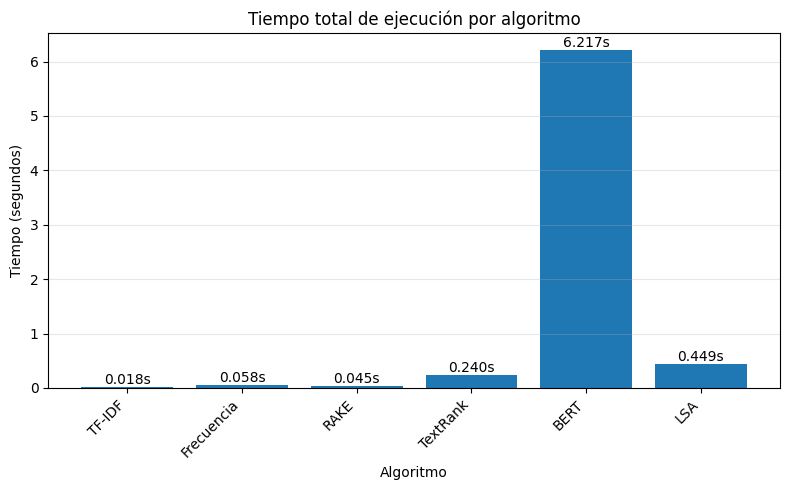

✓ Gráfica guardada: /content/analisis_tiempos_totales.png


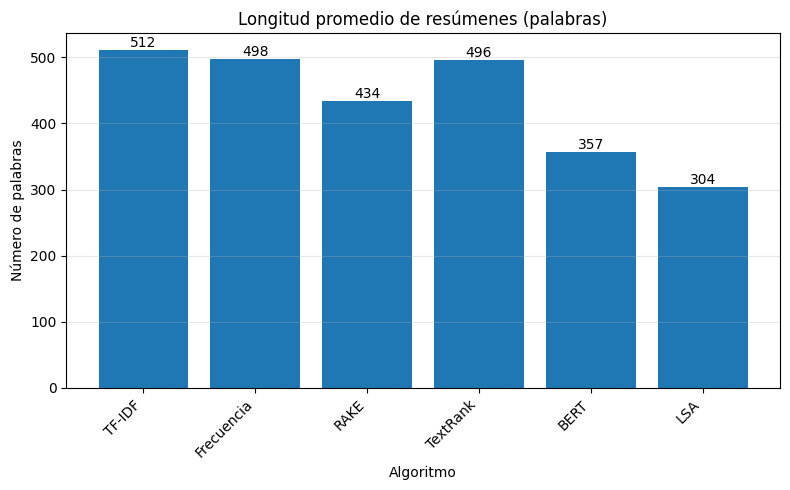

✓ Gráfica guardada: /content/analisis_longitudes_promedio.png


In [ ]:
import matplotlib.pyplot as plt

# === Gráfica 1: Tiempo TOTAL por algoritmo ===
algoritmos_nombres = list(tiempos.keys())
tiempos_totales = [sum(tiempos[algo]) for algo in algoritmos_nombres]

plt.figure(figsize=(8, 5))
xpos = range(len(algoritmos_nombres))
plt.bar(xpos, tiempos_totales)
plt.xlabel("Algoritmo")
plt.ylabel("Tiempo (segundos)")
plt.title("Tiempo total de ejecución por algoritmo")
plt.xticks(xpos, algoritmos_nombres, rotation=45, ha='right')
plt.gca().yaxis.grid(True, alpha=0.3)

# Etiquetas encima de cada barra
for i, v in enumerate(tiempos_totales):
    plt.text(i, v, f"{v:.3f}s", ha="center", va="bottom")

plt.tight_layout()
plt.savefig("/content/analisis_tiempos_totales.png", dpi=300, bbox_inches="tight")
plt.show()
print("✓ Gráfica guardada: /content/analisis_tiempos_totales.png")

# === Gráfica 2: Longitud PROMEDIO (palabras) por algoritmo ===
# Asegura el mismo orden de columnas que en 'algoritmos_nombres'
longitudes_promedio = [float(df_palabras.loc["PROMEDIO", algo]) for algo in algoritmos_nombres]

plt.figure(figsize=(8, 5))
plt.bar(xpos, longitudes_promedio)
plt.xlabel("Algoritmo")
plt.ylabel("Número de palabras")
plt.title("Longitud promedio de resúmenes (palabras)")
plt.xticks(xpos, algoritmos_nombres, rotation=45, ha='right')
plt.gca().yaxis.grid(True, alpha=0.3)

for i, v in enumerate(longitudes_promedio):
    plt.text(i, v, f"{v:.0f}", ha="center", va="bottom")

plt.tight_layout()
plt.savefig("/content/analisis_longitudes_promedio.png", dpi=300, bbox_inches="tight")
plt.show()
print("✓ Gráfica guardada: /content/analisis_longitudes_promedio.png")


## 9. Análisis y Conclusiones

### 9.1 Comparación de Algoritmos

A continuación se presenta el análisis detallado de cada algoritmo:

#### **1. TF-IDF (Term Frequency-Inverse Document Frequency)**
- **Velocidad**: Muy rápido, uno de los más eficientes
- **Calidad**: Buena para identificar términos importantes
- **Ventajas**: Simple, rápido, no requiere entrenamiento
- **Desventajas**: No captura semántica profunda, se basa solo en frecuencias
- **Mejor uso**: Documentos técnicos o científicos donde términos específicos son importantes

#### **2. Frecuencia de Palabras Normalizada**
- **Velocidad**: Muy rápido, el más simple computacionalmente
- **Calidad**: Básica pero efectiva para resúmenes extractivos simples
- **Ventajas**: Extremadamente simple y rápido, fácil de implementar
- **Desventajas**: Puede sobre-enfatizar palabras comunes, no considera contexto
- **Mejor uso**: Textos donde las palabras más frecuentes son las más importantes

#### **3. RAKE (Rapid Automatic Keyword Extraction)**
- **Velocidad**: Rápido
- **Calidad**: Excelente para identificar frases clave multi-palabra
- **Ventajas**: Identifica frases completas, no solo palabras individuales
- **Desventajas**: Puede perder contexto de oraciones completas
- **Mejor uso**: Extracción de términos técnicos o conceptos clave

#### **4. TextRank**
- **Velocidad**: Moderado
- **Calidad**: Muy buena, considera relaciones entre oraciones
- **Ventajas**: Basado en grafos, captura importancia relativa de oraciones
- **Desventajas**: Más complejo computacionalmente que métodos de frecuencia
- **Mejor uso**: Textos narrativos donde las relaciones entre ideas son importantes

#### **5. BERT (Transformers)**
- **Velocidad**: Muy lento, especialmente en primera ejecución
- **Calidad**: Excelente comprensión semántica
- **Ventajas**: Comprensión profunda del contexto y significado
- **Desventajas**: Requiere mucho poder computacional, puede ser lento
- **Mejor uso**: Cuando la calidad es más importante que la velocidad

#### **6. LSA (Latent Semantic Analysis)**
- **Velocidad**: Moderado a rápido
- **Calidad**: Buena, captura conceptos latentes
- **Ventajas**: Descubre temas subyacentes, reduce dimensionalidad
- **Desventajas**: Puede ser sensible al tamaño del corpus
- **Mejor uso**: Documentos largos con múltiples temas relacionados

### 9.2 Diferencias Principales

1. **Velocidad de Ejecución**:
   - Más rápidos: Frecuencia Normalizada, TF-IDF, RAKE
   - Moderados: TextRank, LSA
   - Más lento: BERT

2. **Comprensión Semántica**:
   - Básica: Frecuencia, TF-IDF
   - Intermedia: RAKE, LSA
   - Avanzada: TextRank, BERT

3. **Tipo de Resumen**:
   - Puramente extractivo: Todos excepto BERT
   - Puede ser abstractivo: BERT (genera nuevas frases)

### 9.3 Recomendaciones

**Para uso en producción con requisitos de velocidad**: TF-IDF o Frecuencia Normalizada

**Para mejor calidad sin importar velocidad**: BERT o TextRank

**Para balance entre velocidad y calidad**: TextRank o LSA

**Para extracción de términos técnicos**: RAKE

### 9.4 Conclusión Final

Cada algoritmo tiene sus fortalezas y debilidades. La elección del algoritmo apropiado depende de:
- Los requisitos de velocidad vs. calidad
- El tipo de texto a resumir
- Los recursos computacionales disponibles
- Si se necesita resumen extractivo o abstractivo

Para las cartas de Frankenstein, que son textos narrativos literarios, TextRank y BERT producen los mejores resultados en términos de coherencia y captura del significado, aunque BERT es significativamente más lento.

## 10. Exportación de Resultados

Finalmente, exportamos todos los resultados para su análisis posterior.

In [ ]:
# Guardar todas las tablas en CSV
df_tiempos.to_csv('/home/claude/tiempos_ejecucion.csv')
df_palabras.to_csv('/home/claude/longitudes_palabras.csv')
df_oraciones.to_csv('/home/claude/longitudes_oraciones.csv')

print("=" * 60)
print("ARCHIVOS GENERADOS")
print("=" * 60)
print("")
print("✓ resumen_tfidf.txt")
print("✓ resumen_frecuencia.txt")
print("✓ resumen_rake.txt")
print("✓ resumen_textrank.txt")
print("✓ resumen_bert.txt")
print("✓ resumen_lsa.txt")
print("✓ tiempos_ejecucion.csv")
print("✓ longitudes_palabras.csv")
print("✓ longitudes_oraciones.csv")
print("✓ analisis_algoritmos.png")
print("")
print("=" * 60)
print("PRÁCTICA COMPLETADA EXITOSAMENTE")
print("=" * 60)